Sec 0

In [4]:
import os
import gc
import io
import json
import time
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
from numbers import Integral
from scipy.stats import wilcoxon
import pandas as pd
import seaborn as sns
import xgboost as xgb
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

In [5]:
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore::UserWarning:sklearn.utils.parallel"
sns.set_style("whitegrid")

In [6]:
SEED = 42
np.random.seed(SEED)

BASE_DIR = Path.cwd()
PATHS = {
    "processed": BASE_DIR / "dataset_processed.csv",
    "splits": BASE_DIR / "split_indices.npz",
    "cv_folds": BASE_DIR / "cv_fold_indices.npz",
    "artifact": BASE_DIR / "model_artifact.json",
    "models_dir": BASE_DIR / "models",
    "plots_dir": BASE_DIR / "plots",
}
PATHS["plots_dir"].mkdir(exist_ok=True)

TARGET_FPR = 1e-3

# Selection rule
SELECTION_TOLERANCE_PP = 2.0  # family representative must be within this gap of best TPR
VIABILITY_MAX_DEGRADATION_PP = 0.5  # optimized model cannot lose more OOD TPR
VIABILITY_MIN_REDUCTION_PCT = 20.0  # must actually reduce

# Latency
LATENCY_WARMUP = 20
LATENCY_REPEATS = 200

# CV
N_CV_SPLITS = 5

In [7]:
class LogisticRegressionSGD(ClassifierMixin, BaseEstimator):
    """L2-регуляризованная LogReg, mini-batch SGD, sigmoid, clip + decay.
    predict_proba возвращает (n, 2) как у sklearn."""

    def __init__(
        self,
        lr=0.02,
        n_epochs=50,
        batch_size=1024,
        lambda_reg=5e-4,
        class_weight=None,
        decay=0.99,
        clip_grad=5.0,
        random_state=42,
        verbose=False,
    ):
        self.lr = lr
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.lambda_reg = lambda_reg
        self.class_weight = class_weight
        self.decay = decay
        self.clip_grad = clip_grad
        self.random_state = random_state
        self.verbose = verbose

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    @staticmethod
    def _add_bias(X):
        return np.c_[np.ones(X.shape[0]), X]

    def _loss(self, Xb, y, w):
        p = self._sigmoid(Xb @ self.weights)
        eps = 1e-15
        ll = -np.sum(w * (y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))) / len(y)
        return ll + 0.5 * self.lambda_reg * np.sum(self.weights[1:] ** 2)

    def fit(self, X, y, eval_set=None):
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)

        self.classes_ = np.unique(y)
        if len(self.classes_) != 2:
            raise ValueError(f"Expected 2 classes, got {self.classes_}")

        Xb = self._add_bias(X)
        n, f = Xb.shape
        self.weights = np.zeros(f)

        if self.class_weight:
            w = np.ones(n)
            for cls, cw in self.class_weight.items():
                w[y == cls] = cw
        else:
            w = np.ones(n)

        rng = np.random.RandomState(self.random_state)
        lr = self.lr
        self.loss_history_ = [self._loss(Xb, y, w)]

        # Инициализируем словарь для истории, если передан eval_set
        self.evals_result_ = (
            {"valid_0": {"average_precision": []}} if eval_set else None
        )

        for epoch in range(self.n_epochs):
            order = rng.permutation(n)
            Xs, ys, ws = Xb[order], y[order], w[order]

            for start in range(0, n, self.batch_size):
                end = min(start + self.batch_size, n)
                Xbt, ybt, wbt = Xs[start:end], ys[start:end], ws[start:end]
                p = self._sigmoid(Xbt @ self.weights)
                g = Xbt.T @ (wbt * (p - ybt)) / len(ybt)
                g[1:] += self.lambda_reg * self.weights[1:]
                if self.clip_grad is not None:
                    gn = np.linalg.norm(g)
                    if gn > self.clip_grad:
                        g *= self.clip_grad / gn
                self.weights -= lr * g
            lr *= self.decay
            self.loss_history_.append(self._loss(Xb, y, w))

            if eval_set is not None:
                X_es, y_es = eval_set[0]
                p_es = self.predict_proba(X_es)[:, 1]
                self.evals_result_["valid_0"]["average_precision"].append(
                    average_precision_score(y_es, p_es)
                )

            if self.verbose and epoch % 10 == 0:
                print(
                    f"epoch {epoch:3d} | loss {self.loss_history_[-1]:.6f} | lr {lr:.6f}"
                )

        self.coef_ = self.weights[1:].reshape(1, -1)
        self.intercept_ = np.array([self.weights[0]])

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float32)
        p1 = self._sigmoid(self._add_bias(X) @ self.weights)
        return np.column_stack([1 - p1, p1])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

In [8]:
def build_custom_logreg():
    return LogisticRegressionSGD(
        lr=0.02,
        n_epochs=50,
        batch_size=1024,
        lambda_reg=5e-4,
        decay=0.99,
        clip_grad=5.0,
        random_state=SEED,
        verbose=False,
    )


def build_sk_logreg():
    return SGDClassifier(
        loss="log_loss",
        penalty="l2",
        alpha=0.0001,
        learning_rate="adaptive",
        eta0=0.0005,
        average=True,
        max_iter=1,
        warm_start=True,
        tol=None,
        n_iter_no_change=1000,
        random_state=SEED,
        n_jobs=-1,
    )


def build_rf():
    return RandomForestClassifier(
        n_estimators=10,  # стартовое значение, будем добавлять по 10
        max_depth=15,
        min_samples_leaf=20,
        warm_start=True,
        n_jobs=-1,
        random_state=SEED,
    )


def build_lgbm():
    return lgb.LGBMClassifier(
        n_estimators=5000,
        learning_rate=0.12,
        num_leaves=31,
        min_child_samples=200,
        feature_fraction=0.8,
        bagging_fraction=0.8,
        bagging_freq=5,
        reg_alpha=0.1,
        reg_lambda=1.0,
        importance_type="gain",
        random_state=SEED,
        verbose=-1,
        n_jobs=-1,
    )


def build_xgb():
    early_stop = xgb.callback.EarlyStopping(
        rounds=200,
        min_delta=1e-4,
        save_best=False,
    )
    return xgb.XGBClassifier(
        n_estimators=5000,
        learning_rate=0.12,
        max_depth=6,
        min_child_weight=10,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        tree_method="hist",
        eval_metric="aucpr",
        callbacks=[early_stop],
        random_state=SEED,
        n_jobs=-1,
    )


def build_mlp():
    return MLPClassifier(
        hidden_layer_sizes=(128,),
        activation="relu",
        alpha=1e-4,
        batch_size=2048,
        learning_rate_init=1e-3,
        max_iter=1,
        warm_start=True,
        validation_fraction=0.1,
        random_state=SEED,
    )


MODEL_REGISTRY = {
    "CustomLogReg": {"builder": build_custom_logreg, "scale": True},
    "SkLogReg": {"builder": build_sk_logreg, "scale": True},
    "RandomForest": {"builder": build_rf, "scale": False},
    "LightGBM": {"builder": build_lgbm, "scale": False},
    "XGBoost": {"builder": build_xgb, "scale": False},
    "MLP": {"builder": build_mlp, "scale": True},
}
print(f"Registered models: {list(MODEL_REGISTRY)}")

Registered models: ['CustomLogReg', 'SkLogReg', 'RandomForest', 'LightGBM', 'XGBoost', 'MLP']


In [9]:
def pick_threshold(y_val, y_prob, target_fpr=1e-3):
    fpr, tpr, thr = roc_curve(y_val, y_prob)
    valid = fpr <= target_fpr
    if not valid.any():
        return 0.5, None, None
    idx = np.argmax(tpr * valid)
    return float(thr[idx]), float(fpr[idx]), float(tpr[idx])


def tpr_at_fpr(y_true, y_prob, target_fpr):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    idx = np.searchsorted(fpr, target_fpr, side="right") - 1
    return float(tpr[max(idx, 0)])


def precision_at_recall(y_true, y_prob, target_recall):
    p, r, _ = precision_recall_curve(y_true, y_prob)
    idx = np.searchsorted(-r, -target_recall, side="right") - 1
    return float(p[max(idx, 0)])


def precision_at_prevalence(tpr, fpr, prevalence):
    num = prevalence * tpr
    den = num + (1 - prevalence) * fpr
    return num / den if den > 0 else 0.0


def full_metrics_block(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    m = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "tpr": tp / (tp + fn) if tp + fn else 0.0,
        "fpr": fp / (fp + tn) if fp + tn else 0.0,
        "fp_per_million": (fp / (fp + tn)) * 1e6 if fp + tn else 0.0,
        "brier": brier_score_loss(y_true, y_prob),
    }
    for f in (1e-2, 1e-3, 1e-4):
        m[f"tpr@fpr={f:g}"] = tpr_at_fpr(y_true, y_prob, f)
    for r in (0.95, 0.99):
        m[f"prec@rec={r}"] = precision_at_recall(y_true, y_prob, r)
    for prev in (1e-3, 1e-4):
        m[f"prec@prev={prev:g}"] = precision_at_prevalence(m["tpr"], m["fpr"], prev)
    return m


def per_family_recall(df_test, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    out = {}
    for fam in df_test.loc[df_test["label"] == 1, "class"].unique():
        m = (df_test["class"] == fam).to_numpy()
        out[fam] = float((y_pred[m] == 1).mean())
    return out

Sec 1

In [10]:
full_df = pd.read_csv(PATHS["processed"])
splits = np.load(PATHS["splits"], allow_pickle=True)

train_idx = splits["train_idx"]
val_idx = splits["val_idx"]
test_id_idx = splits["test_id_idx"]
test_ood_idx = splits["test_ood_idx"]

# CV folds — must match models.ipynb
assert PATHS["cv_folds"].exists(), (
    f"Missing {PATHS['cv_folds']}. Run models.ipynb / e2e_models.ipynb first."
)
cv_folds_npz = np.load(PATHS["cv_folds"], allow_pickle=True)
cv_idx = cv_folds_npz["cv_idx"]
assert np.array_equal(cv_idx, np.concatenate([train_idx, val_idx, test_id_idx])), (
    "cv_idx from cv_fold_indices.npz != train+val+test_id from split_indices.npz"
)

with open(PATHS["artifact"], encoding="utf-8") as f:
    artifact = json.load(f)

PRETRAINED_FEAT = artifact["feature_cols"]
PRETRAINED_THRESHOLDS = dict(artifact["thresholds"])

feature_cols_final_all = [c for c in full_df.columns if c.startswith(("nlp_", "isnan_"))]
missing = set(PRETRAINED_FEAT) - set(feature_cols_final_all)
assert not missing, f"Features in artifact missing in df: {missing}"

X_domain = full_df["domain"].values
y_all = full_df["label"].values.astype(np.int64)

y_val      = y_all[val_idx]
y_test_id  = y_all[test_id_idx]
y_test_ood = y_all[test_ood_idx]

df_test_id  = full_df.iloc[test_id_idx].copy()
df_test_ood = full_df.iloc[test_ood_idx].copy()

print(f"df: {full_df.shape} | PRETRAINED_FEAT: {len(PRETRAINED_FEAT)}")
print(f"splits: train={len(train_idx)} val={len(val_idx)} "
      f"test_id={len(test_id_idx)} test_ood={len(test_ood_idx)}")
print(f"cv: {len(cv_idx)} rows | {N_CV_SPLITS} folds")

df: (1999920, 135) | PRETRAINED_FEAT: 130
splits: train=1281254 val=274555 test_id=274555 test_ood=319547
cv: 1830364 rows | 5 folds


In [11]:
trained_models = {}
calibrators = {}
for name in MODEL_REGISTRY:
    pkl = PATHS["models_dir"] / f"{name}.pkl"
    cal = PATHS["models_dir"] / f"{name}_cal.pkl"
    assert pkl.exists(), f"Missing {pkl}"
    trained_models[name] = joblib.load(pkl)
    if cal.exists():
        calibrators[name] = joblib.load(cal)
    print(
        f"{name:15s} | loaded ({type(trained_models[name]).__name__})"
        f"{' + cal' if name in calibrators else ''}"
    )

scaler = joblib.load(BASE_DIR / "scaler.pkl")
print(f"\nscaler: {type(scaler).__name__} | n_features_in_={scaler.n_features_in_}")

CustomLogReg    | loaded (LogisticRegressionSGD) + cal
SkLogReg        | loaded (SGDClassifier) + cal
RandomForest    | loaded (RandomForestClassifier) + cal
LightGBM        | loaded (LGBMClassifier) + cal
XGBoost         | loaded (XGBClassifier) + cal
MLP             | loaded (MLPClassifier) + cal

scaler: StandardScaler | n_features_in_=130


In [12]:
mismatches = []
for name, m in trained_models.items():
    # LGBM
    if hasattr(m, "feature_name_"):
        if list(m.feature_name_) != PRETRAINED_FEAT:
            mismatches.append((name, "feature_name_", len(m.feature_name_)))
    # XGB
    elif hasattr(m, "get_booster"):
        stored = m.get_booster().feature_names
        if stored is not None and list(stored) != PRETRAINED_FEAT:
            mismatches.append((name, "booster.feature_names", len(stored)))
    # sklearn
    elif hasattr(m, "n_features_in_") and m.n_features_in_ != len(PRETRAINED_FEAT):
        mismatches.append((name, "n_features_in_", m.n_features_in_))

assert not mismatches, f"Feature mismatch: {mismatches}"
print(f"All {len(trained_models)} models match PRETRAINED_FEAT")

All 6 models match PRETRAINED_FEAT


In [13]:
def convergence_diagnostic(name, feature_list, max_epochs=80, patience=8, tol=5e-4):
    """Incrementally train `name`, log per-epoch loss / val AP, detect plateau."""
    Xtr_raw = full_df.iloc[train_idx][feature_list].astype("float32")
    Xva_raw = full_df.iloc[val_idx][feature_list].astype("float32")
    ytr = y_all[train_idx]

    if MODEL_REGISTRY[name]["scale"]:
        sc = StandardScaler().fit(Xtr_raw)
        Xtr = sc.transform(Xtr_raw).astype("float32")
        Xva = sc.transform(Xva_raw).astype("float32")
    else:
        Xtr, Xva = Xtr_raw.values, Xva_raw.values

    model = MODEL_REGISTRY[name]["builder"]()
    aps, losses, stopped_reason = [], [], "max_epochs"

    for epoch in range(max_epochs):
        model.fit(Xtr, ytr)
        losses.append(float(model.loss_))
        p = model.predict_proba(Xva)[:, 1]
        aps.append(float(average_precision_score(y_val, p)))

        if epoch < 10 or (epoch + 1) % 5 == 0:
            print(f"  epoch {epoch+1:3d} | loss={losses[-1]:.4f} | val_ap={aps[-1]:.4f}")

        if epoch >= patience and (max(aps[-patience:]) - max(aps[:-patience])) < tol:
            stopped_reason = "plateau"
            print(f"  epoch {epoch+1:3d} | loss={losses[-1]:.4f} | val_ap={aps[-1]:.4f} | stopped")
            break

    ap_30 = aps[min(29, len(aps) - 1)]
    ap_final = max(aps)
    return {
        "model": name,
        "n_features": len(feature_list),
        "epochs_run": len(aps),
        "stopped_reason": stopped_reason,
        "ap_at_30": ap_30,
        "ap_at_plateau": ap_final,
        "gap_pp": (ap_final - ap_30) * 100,
        "aps": aps,
        "losses": losses,
    }


diag_mlp = convergence_diagnostic("MLP", PRETRAINED_FEAT, max_epochs=80)

with open(PATHS["models_dir"] / "convergence_mlp.json", "w") as f:
    json.dump({k: v for k, v in diag_mlp.items() if k not in ("aps", "losses")}, f, indent=2)

  epoch   1 | loss=0.2868 | val_ap=0.9585
  epoch   2 | loss=0.2392 | val_ap=0.9643
  epoch   3 | loss=0.2270 | val_ap=0.9668
  epoch   4 | loss=0.2205 | val_ap=0.9683
  epoch   5 | loss=0.2160 | val_ap=0.9695
  epoch   6 | loss=0.2125 | val_ap=0.9703
  epoch   7 | loss=0.2097 | val_ap=0.9710
  epoch   8 | loss=0.2074 | val_ap=0.9715
  epoch   9 | loss=0.2054 | val_ap=0.9721
  epoch  10 | loss=0.2037 | val_ap=0.9725
  epoch  15 | loss=0.1976 | val_ap=0.9740
  epoch  20 | loss=0.1935 | val_ap=0.9750
  epoch  25 | loss=0.1908 | val_ap=0.9756
  epoch  30 | loss=0.1886 | val_ap=0.9761
  epoch  35 | loss=0.1868 | val_ap=0.9765
  epoch  40 | loss=0.1854 | val_ap=0.9768
  epoch  42 | loss=0.1848 | val_ap=0.9769 | stopped


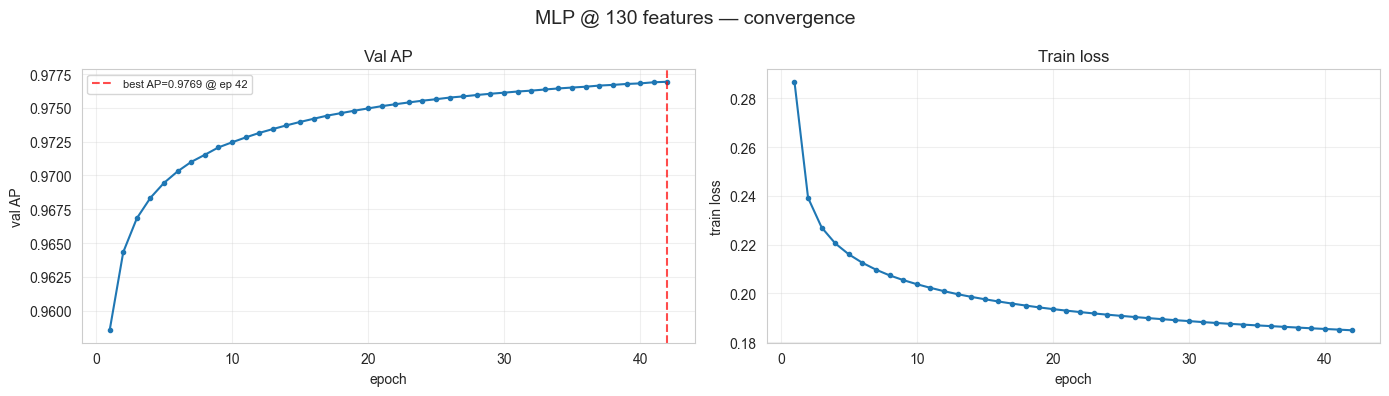

In [14]:
_fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left subplot — val AP
ax = axes[0]
ap = diag_mlp["aps"]
best_i = int(np.argmax(ap))
ax.plot(np.arange(1, len(ap) + 1), ap, marker="o", markersize=3, linewidth=1.5)
ax.axvline(
    best_i + 1,
    color="r", ls="--", alpha=0.7,
    label=f"best AP={ap[best_i]:.4f} @ ep {best_i + 1}",
)
ax.set_title("Val AP")
ax.set_xlabel("epoch")
ax.set_ylabel("val AP")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

# Right subplot — train loss
ax = axes[1]
loss = diag_mlp["losses"]
ax.plot(np.arange(1, len(loss) + 1), loss, marker="o", markersize=3, linewidth=1.5)
ax.set_title("Train loss")
ax.set_xlabel("epoch")
ax.set_ylabel("train loss")
ax.grid(alpha=0.3)

plt.suptitle(f"MLP @ {len(PRETRAINED_FEAT)} features — convergence", fontsize=14)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "convergence_mlp.png", dpi=140)
plt.show()

In [15]:
print(f"epochs_run={diag_mlp['epochs_run']} stopped={diag_mlp['stopped_reason']}")
print(f"ap_at_30={diag_mlp['ap_at_30']:.4f} "
      f"ap_at_plateau={diag_mlp['ap_at_plateau']:.4f} "
      f"gap_pp={diag_mlp['gap_pp']:+.2f}")

epochs_run=42 stopped=plateau
ap_at_30=0.9761 ap_at_plateau=0.9769 gap_pp=+0.08


In [16]:
def get_X_scaled(name, X_raw):
    if MODEL_REGISTRY[name]["scale"]:
        arr = scaler.transform(X_raw).astype("float32")
        return pd.DataFrame(arr, columns=X_raw.columns, index=X_raw.index)
    return X_raw


def _benchmark_latency(model, X_one, X_batch):
    for _ in range(LATENCY_WARMUP):
        _ = model.predict_proba(X_one)
    t0 = time.perf_counter()
    for _ in range(LATENCY_REPEATS):
        _ = model.predict_proba(X_one)
    single_ms = (time.perf_counter() - t0) / LATENCY_REPEATS * 1000

    for _ in range(5):
        _ = model.predict_proba(X_batch)
    t0 = time.perf_counter()
    for _ in range(20):
        _ = model.predict_proba(X_batch)
    batch_1024_s = (time.perf_counter() - t0) / 20

    _buf = io.BytesIO(); joblib.dump(model, _buf)
    size_mb = _buf.tell() / 1e6; del _buf

    return {
        "single_ms": single_ms,
        "batch_1024_s": batch_1024_s,
        "throughput_domains_s": 1024 / batch_1024_s,
        "size_mb": size_mb,
    }


X_val_raw      = full_df.iloc[val_idx][PRETRAINED_FEAT].astype("float32")
X_test_id_raw  = full_df.iloc[test_id_idx][PRETRAINED_FEAT].astype("float32")
X_test_ood_raw = full_df.iloc[test_ood_idx][PRETRAINED_FEAT].astype("float32")

baseline_probs = {"val": {}, "test_id": {}, "test_ood": {}}
baseline_metrics = {}

for name, m in trained_models.items():
    probs = {}
    for split, X_raw in [("val", X_val_raw), ("test_id", X_test_id_raw),
                          ("test_ood", X_test_ood_raw)]:
        p = m.predict_proba(get_X_scaled(name, X_raw))
        p = p[:, 1] if p.ndim == 2 else p
        baseline_probs[split][name] = p
        probs[split] = p

    thr, _, _ = pick_threshold(y_val, probs["val"], TARGET_FPR)
    assert np.isclose(thr, PRETRAINED_THRESHOLDS[name], atol=1e-3), (
        f"{name}: recomputed thr {thr:.4f} != artifact {PRETRAINED_THRESHOLDS[name]:.4f}. "
        "Loaded .pkl differs from artifact."
    )

    m_id = full_metrics_block(y_test_id, probs["test_id"], thr)
    m_od = full_metrics_block(y_test_ood, probs["test_ood"], thr)
    fam  = per_family_recall(df_test_ood, probs["test_ood"], thr)
    lat  = _benchmark_latency(
        m,
        get_X_scaled(name, X_test_ood_raw.iloc[:1]),
        get_X_scaled(name, X_test_ood_raw.iloc[:1024]),
    )
    lat["n_features"] = len(PRETRAINED_FEAT)

    baseline_metrics[name] = {
        "threshold": thr,
        "train_s": float("nan"),
        "latency": lat,
        "metrics_id": m_id,
        "metrics_ood": m_od,
        "per_family_recall_ood": fam,
    }

print("=== Baseline (from .pkl) ===")
for n in sorted(baseline_metrics, key=lambda x: -baseline_metrics[x]["metrics_ood"]["pr_auc"]):
    m = baseline_metrics[n]["metrics_ood"]; lat = baseline_metrics[n]["latency"]
    print(f"  {n:15s} | ood_ap={m['pr_auc']:.4f} | ood_tpr@0.001={m['tpr@fpr=0.001']:.4f} "
          f"| latency={lat['single_ms']:.2f}ms | size={lat['size_mb']:.2f}MB")

=== Baseline (from .pkl) ===
  MLP             | ood_ap=0.9631 | ood_tpr@0.001=0.5728 | latency=0.74ms | size=0.28MB
  LightGBM        | ood_ap=0.9612 | ood_tpr@0.001=0.5863 | latency=1.37ms | size=10.48MB
  XGBoost         | ood_ap=0.9602 | ood_tpr@0.001=0.5872 | latency=3.93ms | size=10.41MB
  RandomForest    | ood_ap=0.9442 | ood_tpr@0.001=0.5127 | latency=16.26ms | size=68.25MB
  CustomLogReg    | ood_ap=0.9377 | ood_tpr@0.001=0.2969 | latency=0.03ms | size=0.00MB
  SkLogReg        | ood_ap=0.9369 | ood_tpr@0.001=0.2798 | latency=0.76ms | size=0.01MB


In [17]:
known_cols = set(PRETRAINED_FEAT) | {"domain", "label", "class"}
extra_cols = [c for c in full_df.columns if c not in known_cols]

print(f"Total columns in full_df: {len(full_df.columns)}")
print(f"- model features (PRETRAINED_FEAT): {len(PRETRAINED_FEAT)}")
print(f"- labels/meta: {len(known_cols - set(PRETRAINED_FEAT))} (domain, label, class)")
print(f"- extra (unused): {len(extra_cols)}")

if extra_cols:
    print("\nExtra columns (dropped from model input):")
    for c in extra_cols:
        print(f"- {c:30s} | dtype={full_df[c].dtype} | n_unique={full_df[c].nunique()}")
    print("\nSample values (first 3 rows):")
    print(full_df[extra_cols].head(3).to_string())
else:
    print("\nNo extra columns")

Total columns in full_df: 135
- model features (PRETRAINED_FEAT): 130
- labels/meta: 3 (domain, label, class)
- extra (unused): 2

Extra columns (dropped from model input):
- nlp_2g_tske                    | dtype=float64 | n_unique=1980747
- nlp_3g_tske                    | dtype=float64 | n_unique=1645891

Sample values (first 3 rows):
   nlp_2g_tske  nlp_3g_tske
0    20.140800   109.492561
1    24.425470   216.000000
2    24.515375   124.036399


Sec 2

In [18]:
print("Computing Spearman correlation on train...")
sample_n = 50_000
rng = np.random.RandomState(SEED)
sample_pos = rng.choice(
    len(train_idx), size=min(sample_n, len(train_idx)), replace=False
)
X_sample = full_df.iloc[train_idx[sample_pos]][PRETRAINED_FEAT].astype("float32")

# Spearman на сэмпле + nan-фичи sentinel=-1 уже заполнены, NaN не будет
corr_matrix = X_sample.corr(method="spearman").abs()
print(f"Correlation matrix: {corr_matrix.shape}")

# Пары с rho > 0.99
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = []
for col in upper.columns:
    for row in upper.index:
        val = upper.loc[row, col]
        if pd.notna(val) and val > 0.99:
            high_corr_pairs.append((row, col, float(val)))
high_corr_pairs.sort(key=lambda x: -x[2])
print(f"\nPairs with |rho| > 0.99: {len(high_corr_pairs)}")
for a, b, r in high_corr_pairs[:20]:
    print(f"  {a:25s} ~ {b:25s} | rho={r:.4f}")

Computing Spearman correlation on train...
Correlation matrix: (130, 130)

Pairs with |rho| > 0.99: 214
  nlp_1g_pstd               ~ nlp_1g_pvar               | rho=1.0000
  nlp_1g_pstd               ~ nlp_1g_qmean              | rho=1.0000
  nlp_1g_pvar               ~ nlp_1g_qmean              | rho=1.0000
  nlp_1g_pstd               ~ nlp_1g_std                | rho=1.0000
  nlp_1g_pvar               ~ nlp_1g_std                | rho=1.0000
  nlp_1g_qmean              ~ nlp_1g_std                | rho=1.0000
  nlp_1g_pstd               ~ nlp_1g_var                | rho=1.0000
  nlp_1g_pvar               ~ nlp_1g_var                | rho=1.0000
  nlp_1g_qmean              ~ nlp_1g_var                | rho=1.0000
  nlp_1g_std                ~ nlp_1g_var                | rho=1.0000
  nlp_2g_dst_ji             ~ nlp_2g_dst_ma             | rho=1.0000
  nlp_2g_pstd               ~ nlp_2g_pvar               | rho=1.0000
  nlp_2g_pstd               ~ nlp_2g_qmean              | rho=1.0000

In [19]:
# distance = 1 - |rho|, квадратная форма для linkage
dist_matrix = 1.0 - corr_matrix.fillna(0).values
np.fill_diagonal(dist_matrix, 0)
dist_matrix = np.clip(dist_matrix, 0, 1)

# condensed form
condensed = squareform(dist_matrix, checks=False)
Z = linkage(condensed, method="average")

clusters_at = {}
for thr in [0.99, 0.95, 0.90]:
    labels = fcluster(Z, t=1 - thr, criterion="distance")
    clusters_at[thr] = pd.Series(labels, index=corr_matrix.columns)
    n_clusters = len(np.unique(labels))
    sizes = pd.Series(labels).value_counts()
    print(
        f"rho > {thr}: {n_clusters} clusters | "
        f"largest={sizes.iloc[0]}, median={sizes.median():.0f}"
    )

rho > 0.99: 78 clusters | largest=15, median=1
rho > 0.95: 64 clusters | largest=25, median=1
rho > 0.9: 56 clusters | largest=28, median=1


In [20]:
feature_summary = pd.DataFrame(index=PRETRAINED_FEAT)

# Native importance (5 models; MLP = permutation)
for name in MODEL_REGISTRY:
    m = trained_models[name]
    if name == "LightGBM":
        imp = pd.Series(
            m.booster_.feature_importance(importance_type="gain"), index=PRETRAINED_FEAT
        )
    elif name in ("XGBoost", "RandomForest"):
        imp = pd.Series(m.feature_importances_, index=PRETRAINED_FEAT)
    elif name in ("CustomLogReg", "SkLogReg"):
        coef = m.coef_[0] if name == "SkLogReg" else m.weights[1:]
        imp = pd.Series(np.abs(coef), index=PRETRAINED_FEAT)
    else:  # MLP — permutation on VAL
        X_perm = get_X_scaled(name, X_val_raw)
        perm_idx = rng.choice(len(X_perm), size=10_000, replace=False)
        pi = permutation_importance(
            m, X_perm.iloc[perm_idx], y_val[perm_idx],
            scoring="average_precision", n_repeats=3, random_state=SEED,
            n_jobs=1,
        )
        imp = pd.Series(pi.importances_mean, index=PRETRAINED_FEAT)

        # Сheck
        if imp.abs().sum() < 1e-6:
            print(f"{name}: permutation returned all zeros."
                  f"shape={pi.importances.shape}, sample={pi.importances[:3]}")
            raise RuntimeError(f"permutation_importance failed for {name}")
    feature_summary[f"imp_{name}"] = imp.values
    feature_summary[f"rank_{name}"] = imp.rank(ascending=False).values

# Consensus
rank_cols = [c for c in feature_summary.columns if c.startswith("rank_")]
feature_summary["mean_rank"] = feature_summary[rank_cols].mean(axis=1)
feature_summary["n_top_20"] = (feature_summary[rank_cols] <= 20).sum(axis=1)
feature_summary["n_top_50"] = (feature_summary[rank_cols] <= 50).sum(axis=1)

feature_summary = feature_summary.sort_values("mean_rank")
print("=== Top-20 by consensus ===")
print(feature_summary[["mean_rank", "n_top_20"]].head(20).round(1).to_string())

=== Top-20 by consensus ===
                mean_rank  n_top_20
nlp_r_sym_fqdn        7.3         6
nlp_lc_c              9.7         5
nlp_l_2dn            13.7         5
nlp_3g_norm          16.5         4
nlp_2g_e             17.3         4
nlp_1g_dst_em        18.3         4
nlp_l_odn            20.7         3
nlp_r_sym_2dn        21.0         3
nlp_3g_e             22.5         4
nlp_3g_tpstd         23.3         4
nlp_2g_dst_em        24.8         4
nlp_r_let_fqdn       26.7         4
nlp_2g_dist          27.7         3
nlp_r_con_2dn        29.5         3
nlp_3g_pro           29.5         3
nlp_lc_n             31.3         2
nlp_2g_pea           31.5         2
nlp_r_num_fqdn       31.7         3
nlp_3g_tsum          32.0         3
nlp_2g_norm          32.5         3


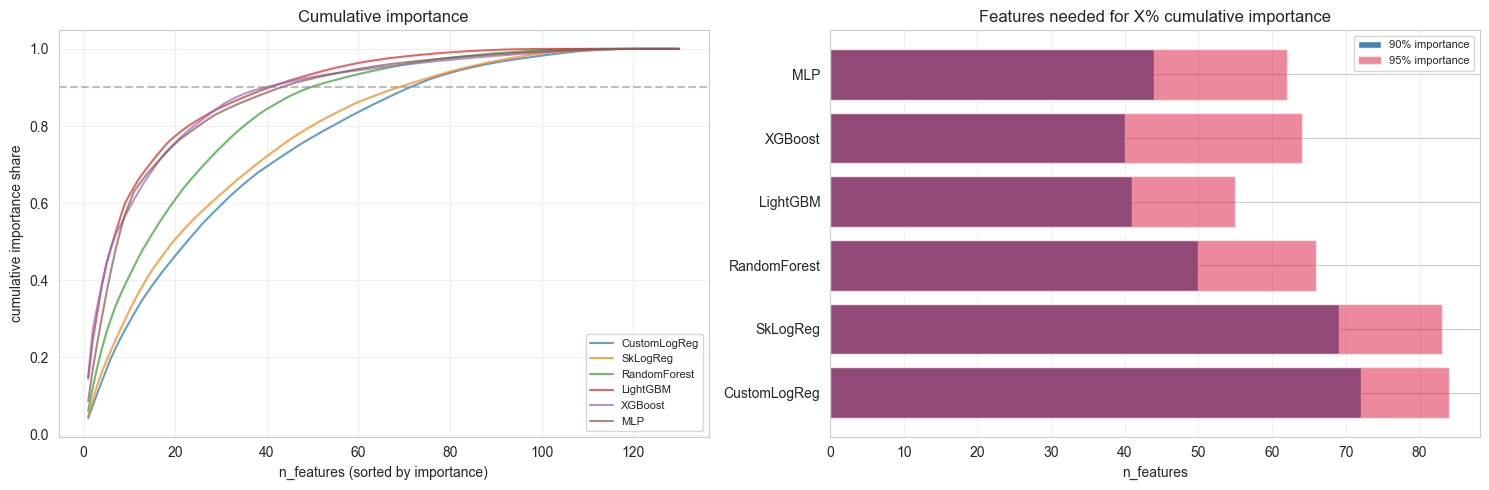

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: AP vs n_features — only "importance >= threshold"
ax = axes[0]
for name in MODEL_REGISTRY:
    imp_col = f"imp_{name}"
    if imp_col not in feature_summary:
        continue
    vals = feature_summary[imp_col].values
    order = np.argsort(-vals)
    cumsum = np.cumsum(vals[order]) / (vals.sum() + 1e-9)
    ax.plot(np.arange(1, len(cumsum) + 1), cumsum, label=name, alpha=0.7, linewidth=1.5)
ax.set_xlabel("n_features (sorted by importance)")
ax.set_ylabel("cumulative importance share")
ax.set_title("Cumulative importance")
ax.axhline(0.9, color="gray", ls="--", alpha=0.5)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# Right: count features for 90% importance for each model
ax = axes[1]
thresholds_needed = {}
for name in MODEL_REGISTRY:
    imp_col = f"imp_{name}"
    if imp_col not in feature_summary:
        continue
    vals = feature_summary[imp_col].values
    order = np.argsort(-vals)
    cumsum = np.cumsum(vals[order]) / (vals.sum() + 1e-9)
    n_for_90 = int(np.searchsorted(cumsum, 0.9) + 1)
    n_for_95 = int(np.searchsorted(cumsum, 0.95) + 1)
    thresholds_needed[name] = {"n_for_90pct": n_for_90, "n_for_95pct": n_for_95}

ax.barh(
    list(thresholds_needed),
    [v["n_for_90pct"] for v in thresholds_needed.values()],
    color="steelblue",
    label="90% importance",
)
ax.barh(
    list(thresholds_needed),
    [v["n_for_95pct"] for v in thresholds_needed.values()],
    color="crimson",
    alpha=0.5,
    label="95% importance",
)
ax.set_xlabel("n_features")
ax.set_title("Features needed for X% cumulative importance")
ax.legend(fontsize=8)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "cumulative_importance.png", dpi=140)
plt.show()

In [22]:
print("=== Features needed for 90%/95% importance ===")
for n, v in thresholds_needed.items():
    print(f"  {n:15s} | 90%: {v['n_for_90pct']:3d} | 95%: {v['n_for_95pct']:3d}")

=== Features needed for 90%/95% importance ===
  CustomLogReg    | 90%:  72 | 95%:  84
  SkLogReg        | 90%:  69 | 95%:  83
  RandomForest    | 90%:  50 | 95%:  66
  LightGBM        | 90%:  41 | 95%:  55
  XGBoost         | 90%:  40 | 95%:  64
  MLP             | 90%:  44 | 95%:  62


In [23]:
imp_mlp = feature_summary["imp_MLP"].values
print(f"imp_MLP.sum()   = {imp_mlp.sum():+.6f}       ← ключевое")
print(f"imp_MLP.min/max = {imp_mlp.min():+.6f} / {imp_mlp.max():+.6f}")
print(f"#positive / #negative = {(imp_mlp > 0).sum()} / {(imp_mlp < 0).sum()}")
print(f"#exactly-zero         = {(imp_mlp == 0).sum()}")

# Cumsum check
vals = imp_mlp
order = np.argsort(-vals)
cumsum = np.cumsum(vals[order]) / (vals.sum() + 1e-9)
print(f"\ncumsum is monotonic: {bool(np.all(np.diff(cumsum) >= 0))}")
print(f"cumsum[-1] = {cumsum[-1]:.4f}")
print(f"first index where cumsum >= 0.9: {np.searchsorted(cumsum, 0.9)}")

imp_MLP.sum()   = +1.914946       ← ключевое
imp_MLP.min/max = +0.000000 / +0.165310
#positive / #negative = 120 / 0
#exactly-zero         = 10

cumsum is monotonic: True
cumsum[-1] = 1.0000
first index where cumsum >= 0.9: 43


Sec 3

In [24]:
def fit_model(model, name, X_tr, y_tr, X_va, y_va, seed=SEED):
    Xtr_v = X_tr.values if hasattr(X_tr, "values") else X_tr
    Xva_v = X_va.values if hasattr(X_va, "values") else X_va
    rng = np.random.RandomState(seed)

    if name == "CustomLogReg":
        model.fit(Xtr_v, y_tr, eval_set=[(Xva_v, y_va)])
    elif name == "SkLogReg":
        for _ in range(50):
            idx = rng.permutation(len(X_tr))
            model.partial_fit(X_tr.iloc[idx], y_tr[idx], classes=[0, 1])
    elif name == "RandomForest":
        for _ in range(10):
            model.set_params(n_estimators=model.n_estimators + 10)
            model.fit(X_tr, y_tr)
    elif name == "LightGBM":
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)],
                  eval_metric="average_precision",
                  callbacks=[lgb.early_stopping(200, verbose=False), lgb.log_evaluation(0)])
    elif name == "XGBoost":
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    elif name == "MLP":
        for _ in range(30):
            model.fit(X_tr, y_tr)
    return model


def predict_proba_1d(model, X):
    p = model.predict_proba(X)
    return p[:, 1] if p.ndim == 2 else p


def evaluate_feature_set(feature_list, label, models=None, seed=SEED):
    if models is None:
        models = list(MODEL_REGISTRY)

    X_tr_raw = full_df.iloc[train_idx][feature_list].astype("float32")
    X_va_raw = full_df.iloc[val_idx][feature_list].astype("float32")
    X_id_raw = full_df.iloc[test_id_idx][feature_list].astype("float32")
    X_od_raw = full_df.iloc[test_ood_idx][feature_list].astype("float32")

    results = {"label": label, "n_features": len(feature_list), "models": {}}
    print(f"\n{'=' * 60}\n{label} | n_features={len(feature_list)}\n{'=' * 60}")

    for name in models:
        cfg = MODEL_REGISTRY[name]
        if cfg["scale"]:
            sc = StandardScaler().fit(X_tr_raw)
            Xtr = pd.DataFrame(sc.transform(X_tr_raw), columns=feature_list)
            Xva = pd.DataFrame(sc.transform(X_va_raw), columns=feature_list)
            Xid = pd.DataFrame(sc.transform(X_id_raw), columns=feature_list)
            Xod = pd.DataFrame(sc.transform(X_od_raw), columns=feature_list)
        else:
            Xtr, Xva, Xid, Xod = X_tr_raw, X_va_raw, X_id_raw, X_od_raw

        model = cfg["builder"]()
        t0 = time.perf_counter()
        model = fit_model(model, name, Xtr, y_all[train_idx], Xva, y_val, seed=seed)
        train_s = time.perf_counter() - t0

        p_val = predict_proba_1d(model, Xva)
        p_id  = predict_proba_1d(model, Xid)
        p_od  = predict_proba_1d(model, Xod)

        thr, _, _ = pick_threshold(y_val, p_val, TARGET_FPR)
        m_id = full_metrics_block(y_test_id, p_id, thr)
        m_od = full_metrics_block(y_test_ood, p_od, thr)
        fam  = per_family_recall(df_test_ood, p_od, thr)
        lat  = _benchmark_latency(model, Xod.iloc[:1], Xod.iloc[:1024])
        lat["n_features"] = len(feature_list)

        results["models"][name] = {
            "model": model,
            "threshold": thr,
            "train_s": train_s,
            "metrics_id": m_id,
            "metrics_ood": m_od,
            "per_family_recall_ood": fam,
            "probs": {"val": p_val, "test_id": p_id, "test_ood": p_od},
            "latency": lat,
        }
        print(f"  {name:15s} | id_ap={m_id['pr_auc']:.4f} | ood_ap={m_od['pr_auc']:.4f} "
              f"| ood_tpr@0.001={m_od['tpr@fpr=0.001']:.4f} | {train_s:.0f}s "
              f"| {lat['single_ms']:.2f}ms | {lat['size_mb']:.2f}MB")
        gc.collect()
    return results


def build_feats_reduced(feature_list, summary_df, top_pct=0.30, protect_clusters=None):
    """Cluster protection restricted to feature_list, so it cannot blow up the target size."""
    n_keep = int(len(feature_list) * (1 - top_pct))
    ranked = summary_df.loc[feature_list].sort_values("mean_rank").index.tolist()
    kept = set(ranked[:n_keep])
    if protect_clusters is not None:
        pc = protect_clusters[protect_clusters.index.isin(feature_list)]
        for cid in pc.unique():
            members = pc[pc == cid].index.tolist()
            if not any(m in kept for m in members):
                rep = next(m for m in ranked if m in members)
                kept.add(rep)
    return [c for c in ranked if c in kept]

In [25]:
stage_results = {}

stage_results["S0_baseline"] = {
    "label": "S0_baseline",
    "n_features": len(PRETRAINED_FEAT),
    "models": {
        n: {
            "metrics_id": baseline_metrics[n]["metrics_id"],
            "metrics_ood": baseline_metrics[n]["metrics_ood"],
            "per_family_recall_ood": baseline_metrics[n]["per_family_recall_ood"],
            "threshold": baseline_metrics[n]["threshold"],
            "train_s": baseline_metrics[n]["train_s"],
            "latency": baseline_metrics[n]["latency"],
            "probs": {s: baseline_probs[s][n] for s in ("val", "test_id", "test_ood")},
        }
        for n in MODEL_REGISTRY
    },
}

drop_dupes = set()
for a, b, _ in high_corr_pairs:
    ra = feature_summary.loc[a, "mean_rank"]; rb = feature_summary.loc[b, "mean_rank"]
    drop_dupes.add(b if ra < rb else a)
feats_s1 = [c for c in PRETRAINED_FEAT if c not in drop_dupes]
stage_results["S1_no_dupes"] = evaluate_feature_set(feats_s1, "S1_no_dupes")

clusters_095 = clusters_at[0.95]
feats_s2 = build_feats_reduced(feats_s1, feature_summary, top_pct=0.30,
                                protect_clusters=clusters_095)
stage_results["S2_top70pct"] = evaluate_feature_set(feats_s2, "S2_top70pct")

FEATURE_GROUPS = {
    "1g": [c for c in PRETRAINED_FEAT if c.startswith("nlp_1g_")],
    "2g": [c for c in PRETRAINED_FEAT if c.startswith("nlp_2g_")],
    "3g": [c for c in PRETRAINED_FEAT if c.startswith("nlp_3g_")],
    "len": [c for c in PRETRAINED_FEAT if c.startswith(("nlp_l_", "nlp_lc_", "nlp_n"))],
    "ratio": [c for c in PRETRAINED_FEAT if c.startswith("nlp_r_")],
    "isnan": [c for c in PRETRAINED_FEAT if c.startswith("isnan_")],
}
for grp in ["isnan", "ratio", "len", "3g"]:
    feats = [c for c in feats_s2 if c not in FEATURE_GROUPS[grp]]
    stage_results[f"S3_no_{grp}"] = evaluate_feature_set(feats, f"S3_no_{grp}")


S1_no_dupes | n_features=77
  CustomLogReg    | id_ap=0.9158 | ood_ap=0.9352 | ood_tpr@0.001=0.2809 | 51s | 0.03ms | 0.00MB
  SkLogReg        | id_ap=0.9164 | ood_ap=0.9311 | ood_tpr@0.001=0.2239 | 57s | 0.61ms | 0.00MB
  RandomForest    | id_ap=0.9622 | ood_ap=0.9464 | ood_tpr@0.001=0.5226 | 108s | 16.07ms | 69.37MB
  LightGBM        | id_ap=0.9811 | ood_ap=0.9599 | ood_tpr@0.001=0.5822 | 199s | 1.29ms | 17.78MB
  XGBoost         | id_ap=0.9806 | ood_ap=0.9594 | ood_tpr@0.001=0.5857 | 276s | 3.00ms | 10.69MB
  MLP             | id_ap=0.9750 | ood_ap=0.9671 | ood_tpr@0.001=0.5807 | 87s | 0.62ms | 0.17MB

S2_top70pct | n_features=74
  CustomLogReg    | id_ap=0.9154 | ood_ap=0.9352 | ood_tpr@0.001=0.2801 | 50s | 0.04ms | 0.00MB
  SkLogReg        | id_ap=0.9160 | ood_ap=0.9315 | ood_tpr@0.001=0.2214 | 55s | 0.60ms | 0.00MB
  RandomForest    | id_ap=0.9622 | ood_ap=0.9467 | ood_tpr@0.001=0.5198 | 107s | 16.21ms | 69.86MB
  LightGBM        | id_ap=0.9810 | ood_ap=0.9598 | ood_tpr@0.001=0.5

In [26]:
def build_stage_table(stage_results, metric="pr_auc"):
    rows = []
    for label, r in stage_results.items():
        for name, m in r["models"].items():
            n_feat = (int(r["n_features"]) if isinstance(r["n_features"], Integral)
                      else int(r["n_features"].get(name, len(PRETRAINED_FEAT))))
            lat = m.get("latency") or {}
            rows.append({
                "stage": label, "model": name, "n_features": n_feat,
                "id_ap": m["metrics_id"][metric],
                "ood_ap": m["metrics_ood"][metric],
                "ood_tpr@1e-3": m["metrics_ood"]["tpr@fpr=0.001"],
                "ood_fpr": m["metrics_ood"]["fpr"],
                "ood_brier": m["metrics_ood"]["brier"],
                "train_s": m["train_s"],
                "single_ms": lat.get("single_ms", float("nan")),
                "size_mb": lat.get("size_mb", float("nan")),
            })
    return pd.DataFrame(rows)


stage_table = build_stage_table(stage_results)

print("=== OOD AP by model × stage ===")
pivot_ood = stage_table.pivot_table(index="model", columns="stage", values="ood_ap")
print(pivot_ood.round(4).to_string())

print("\n=== OOD TPR@FPR=1e-3 by model × stage ===")
pivot_tpr = stage_table.pivot_table(index="model", columns="stage", values="ood_tpr@1e-3")
print(pivot_tpr.round(4).to_string())

baseline_ood = {n: baseline_metrics[n]["metrics_ood"]["pr_auc"] for n in MODEL_REGISTRY}
baseline_tpr = {n: baseline_metrics[n]["metrics_ood"]["tpr@fpr=0.001"] for n in MODEL_REGISTRY}

delta_table = stage_table.copy()
delta_table["delta_ood_ap_pp"] = delta_table.apply(
    lambda r: (r["ood_ap"] - baseline_ood[r["model"]]) * 100, axis=1)
delta_table["delta_ood_tpr_pp"] = delta_table.apply(
    lambda r: (r["ood_tpr@1e-3"] - baseline_tpr[r["model"]]) * 100, axis=1)

pivot_delta_ap = delta_table.pivot_table(
    index="model", columns="stage", values="delta_ood_ap_pp")
pivot_delta_tpr = delta_table.pivot_table(
    index="model", columns="stage", values="delta_ood_tpr_pp")

print("\n=== Δ OOD AP vs baseline (pp) ===")
print(pivot_delta_ap.round(2).to_string())
print("\n=== Δ OOD TPR@FPR=1e-3 vs baseline (pp) ===")
print(pivot_delta_tpr.round(2).to_string())

=== OOD AP by model × stage ===
stage         S0_baseline  S1_no_dupes  S2_top70pct  S3_no_3g  S3_no_isnan  S3_no_len  S3_no_ratio
model                                                                                             
CustomLogReg       0.9377       0.9352       0.9352    0.9300       0.9351     0.9283       0.9313
LightGBM           0.9612       0.9599       0.9598    0.9543       0.9598     0.9557       0.9612
MLP                0.9631       0.9671       0.9673    0.9619       0.9675     0.9629       0.9679
RandomForest       0.9442       0.9464       0.9467    0.9420       0.9473     0.9443       0.9490
SkLogReg           0.9369       0.9311       0.9315    0.9252       0.9311     0.9242       0.9287
XGBoost            0.9602       0.9594       0.9598    0.9531       0.9606     0.9557       0.9610

=== OOD TPR@FPR=1e-3 by model × stage ===
stage         S0_baseline  S1_no_dupes  S2_top70pct  S3_no_3g  S3_no_isnan  S3_no_len  S3_no_ratio
model                             

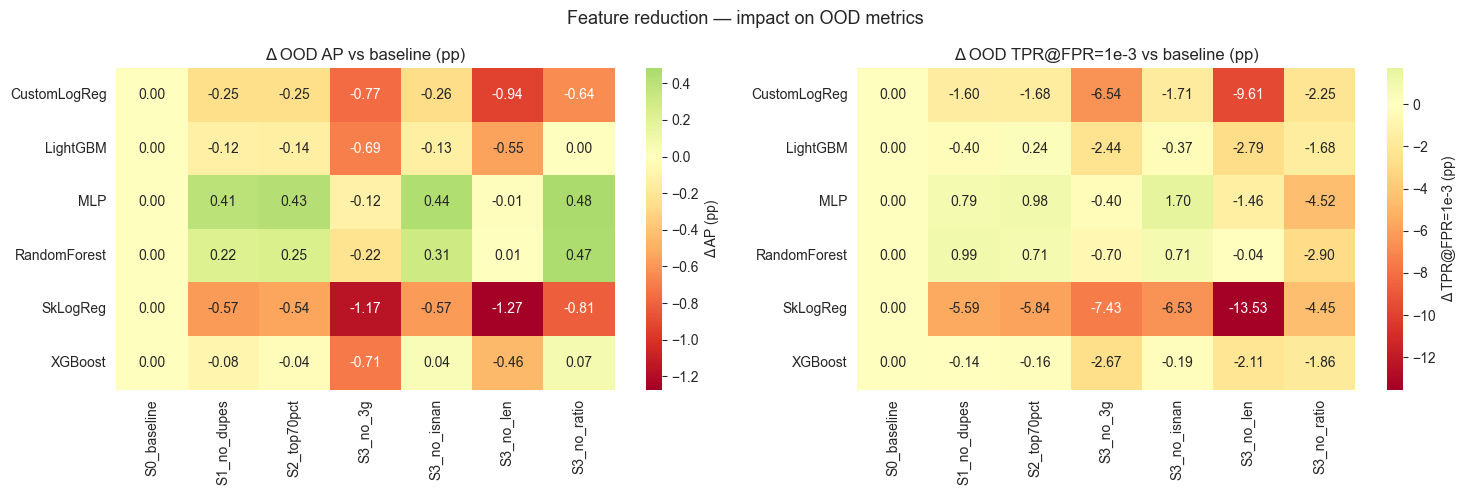

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(pivot_delta_ap, annot=True, fmt=".2f", cmap="RdYlGn", center=0,
            ax=axes[0], cbar_kws={"label": "Δ AP (pp)"})
axes[0].set_title("Δ OOD AP vs baseline (pp)")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

sns.heatmap(pivot_delta_tpr, annot=True, fmt=".2f", cmap="RdYlGn", center=0,
            ax=axes[1], cbar_kws={"label": "Δ TPR@FPR=1e-3 (pp)"})
axes[1].set_title("Δ OOD TPR@FPR=1e-3 vs baseline (pp)")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.suptitle("Feature reduction — impact on OOD metrics", fontsize=13)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "reduction_heatmap.png", dpi=140)
plt.show()

Sec 4

In [28]:
rank_cols = [c for c in feature_summary.columns if c.startswith("rank_")]
top30_mask = feature_summary[rank_cols] <= 30
feature_summary["n_top_30"] = top30_mask.sum(axis=1)
feature_summary["n_top_10"] = (feature_summary[rank_cols] <= 10).sum(axis=1)

core_set = feature_summary[feature_summary["n_top_30"] >= 5].index.tolist()
consensus_5_of_6 = feature_summary[feature_summary["n_top_30"] >= 5].shape[0]
consensus_6_of_6 = feature_summary[feature_summary["n_top_30"] == 6].shape[0]
print(f"Features in top-30 for 5/6 models: {consensus_5_of_6}")
print(f"Features in top-30 for 6/6 models: {consensus_6_of_6}")
print(f"\nCore set (5+ of 6): {core_set}")

# Model-specific features (top-10, deduped, outside core set)
CORE_SET = set(core_set)
UNIQUE_FEATURES = {c for c in PRETRAINED_FEAT if c not in drop_dupes}

model_specific = {}
for name in MODEL_REGISTRY:
    top10 = feature_summary[feature_summary[f"rank_{name}"] <= 10].index.tolist()
    # Exclude duplicates (keep only one representative per rho>0.99 cluster)
    top10_unique = [c for c in top10 if c in UNIQUE_FEATURES]
    # Exclude core set — we want what's *specific* to this model
    model_specific[name] = [c for c in top10_unique if c not in CORE_SET]

print("\n=== Model-specific features (top-10, deduped, excluding core set) ===")
for n, feats in model_specific.items():
    marker = "- (core set only)" if not feats else ""
    print(f" {n:15s} | {feats}{marker}")

Features in top-30 for 5/6 models: 7
Features in top-30 for 6/6 models: 2

Core set (5+ of 6): ['nlp_r_sym_fqdn', 'nlp_lc_c', 'nlp_l_2dn', 'nlp_2g_e', 'nlp_r_sym_2dn', 'nlp_3g_e', 'nlp_2g_pea']

=== Model-specific features (top-10, deduped, excluding core set) ===
 CustomLogReg    | ['nlp_1g_dst_em', 'nlp_l_odn', 'nlp_3g_tpstd', 'nlp_2g_dst_em', 'nlp_1g_tsum']
 SkLogReg        | ['nlp_1g_dst_em', 'nlp_l_odn', 'nlp_2g_dst_em', 'nlp_1g_e']
 RandomForest    | ['nlp_3g_norm', 'nlp_r_let_fqdn', 'nlp_2g_norm']
 LightGBM        | ['nlp_3g_norm', 'nlp_r_let_fqdn', 'nlp_2g_norm']
 XGBoost         | ['nlp_r_let_fqdn', 'nlp_2g_dist', 'nlp_r_vow_odn']
 MLP             | ['nlp_1g_dst_em', 'nlp_l_odn', 'nlp_3g_tpstd', 'nlp_2g_dst_em']


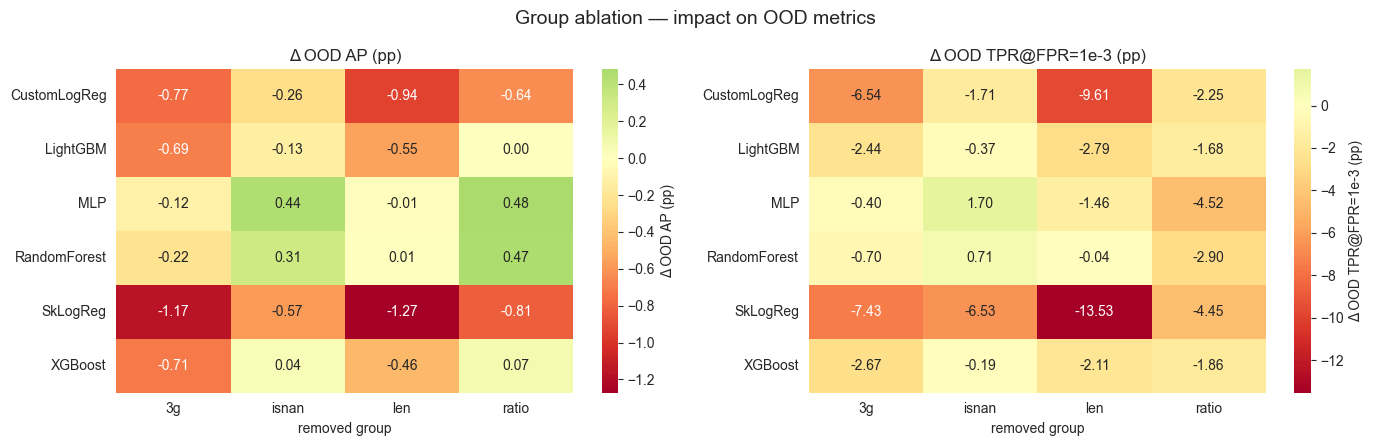

In [30]:
group_delta = delta_table[delta_table["stage"].str.startswith("S3_no_")].copy()
group_delta["group"] = group_delta["stage"].str.replace("S3_no_", "", regex=False)

pivot_group_ap = group_delta.pivot_table(
    index="model", columns="group", values="delta_ood_ap_pp"
)
pivot_group_tpr = group_delta.pivot_table(
    index="model", columns="group", values="delta_ood_tpr_pp"
)

_fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (title, pivot) in zip(
    axes,
    [
        ("Δ OOD AP (pp)", pivot_group_ap),
        ("Δ OOD TPR@FPR=1e-3 (pp)", pivot_group_tpr),
    ],
):
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".2f",
        cmap="RdYlGn",
        center=0,
        cbar_kws={"label": title},
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("removed group")
    ax.set_ylabel("")

plt.suptitle("Group ablation — impact on OOD metrics", fontsize=14)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "group_ablation.png", dpi=140)
plt.show()

In [31]:
sens = (
    delta_table.query("stage != 'S0_baseline'")
    .groupby("model")
    .agg(
        mean_abs_delta_ap_pp=("delta_ood_ap_pp", lambda s: s.abs().mean()),
        mean_abs_delta_tpr_pp=("delta_ood_tpr_pp", lambda s: s.abs().mean()),
        worst_ap_pp=("delta_ood_ap_pp", "min"),
        best_ap_pp=("delta_ood_ap_pp", "max"),
    )
    .astype(float)
)
assert sens.index.is_unique
print("=== Model sensitivity to feature reduction ===")
print(sens.round(2).to_string())

=== Model sensitivity to feature reduction ===
              mean_abs_delta_ap_pp  mean_abs_delta_tpr_pp  worst_ap_pp  best_ap_pp
model                                                                             
CustomLogReg                  0.52                   3.90        -0.94       -0.25
LightGBM                      0.27                   1.32        -0.69        0.00
MLP                           0.31                   1.64        -0.12        0.48
RandomForest                  0.25                   1.01        -0.22        0.47
SkLogReg                      0.82                   7.23        -1.27       -0.54
XGBoost                       0.23                   1.19        -0.71        0.07


Sec 5

In [32]:
MODEL_FAMILY = {
    "CustomLogReg": "linear", "SkLogReg": "linear",
    "RandomForest": "tree",   "LightGBM": "tree",  "XGBoost": "tree",
    "MLP": "neural",
}

selection_df = pd.DataFrame({
    "ood_tpr@1e-3": {n: baseline_metrics[n]["metrics_ood"]["tpr@fpr=0.001"] for n in MODEL_REGISTRY},
    "ood_pr_auc": {n: baseline_metrics[n]["metrics_ood"]["pr_auc"] for n in MODEL_REGISTRY},
    "ood_brier": {n: baseline_metrics[n]["metrics_ood"]["brier"] for n in MODEL_REGISTRY},
    "single_ms": {n: baseline_metrics[n]["latency"]["single_ms"] for n in MODEL_REGISTRY},
    "size_mb": {n: baseline_metrics[n]["latency"]["size_mb"] for n in MODEL_REGISTRY},
    "family": {n: MODEL_FAMILY[n] for n in MODEL_REGISTRY},
}).sort_values("ood_tpr@1e-3", ascending=False)

print("=== Baseline ranking (primary = ood_tpr@fpr=1e-3) ===")
print(selection_df.round(4).to_string())

best_tpr = selection_df["ood_tpr@1e-3"].max()
print(f"\nRule: best-in-family with gap to best TPR ≤ {SELECTION_TOLERANCE_PP}pp")

selected_models = []
for family in ["tree", "neural", "linear"]:
    fam = selection_df[selection_df["family"] == family]
    if len(fam) == 0: continue
    rep = fam.index[0]
    gap_pp = (best_tpr - fam.loc[rep, "ood_tpr@1e-3"]) * 100
    ok = gap_pp <= SELECTION_TOLERANCE_PP
    print(f"  {family:8s} | {rep:15s} | gap={gap_pp:+6.2f}pp | "
          f"{'SELECTED' if ok else 'excluded'}")
    if ok: selected_models.append(rep)

assert len(selected_models) >= 2, f"Selection picked <2 models: {selected_models}"
print(f"\nSelected: {selected_models}")

=== Baseline ranking (primary = ood_tpr@fpr=1e-3) ===
              ood_tpr@1e-3  ood_pr_auc  ood_brier  single_ms  size_mb  family
XGBoost             0.5872      0.9602     0.0923     3.9327  10.4108    tree
LightGBM            0.5863      0.9612     0.0911     1.3738  10.4829    tree
MLP                 0.5728      0.9631     0.0868     0.7408   0.2809  neural
RandomForest        0.5127      0.9442     0.1116    16.2638  68.2543    tree
CustomLogReg        0.2969      0.9377     0.1145     0.0331   0.0043  linear
SkLogReg            0.2798      0.9369     0.1154     0.7596   0.0051  linear

Rule: best-in-family with gap to best TPR ≤ 2.0pp
  tree     | XGBoost         | gap= +0.00pp | SELECTED
  neural   | MLP             | gap= +1.44pp | SELECTED
  linear   | CustomLogReg    | gap=+29.02pp | excluded

Selected: ['XGBoost', 'MLP']


In [33]:
feats_s3_no_ratio = [c for c in feats_s2 if c not in FEATURE_GROUPS["ratio"]]
print(f"Base feature set (S3_no_ratio): {len(feats_s3_no_ratio)} features")

K_SWEEP = sorted({min(k, len(feats_s3_no_ratio))
                  for k in [30, 40, 50, 60, len(feats_s3_no_ratio)]})

ksweep_results = {name: {} for name in selected_models}

for name in selected_models:
    print(f"\n{'=' * 60}\n{name} — K-sweep on S3_no_ratio\n{'=' * 60}")
    imp_sorted = feature_summary.loc[feats_s3_no_ratio, f"imp_{name}"].sort_values(ascending=False)

    for k in K_SWEEP:
        selected = imp_sorted.head(k).index.tolist()
        res = evaluate_feature_set(selected, f"S5_{name}_K{k}", models=[name])
        m = res["models"][name]
        ksweep_results[name][k] = {
            "features": selected,
            "n_features": k,
            "id_ap": m["metrics_id"]["pr_auc"],
            "ood_ap": m["metrics_ood"]["pr_auc"],
            "ood_tpr@1e-3": m["metrics_ood"]["tpr@fpr=0.001"],
            "ood_fpr": m["metrics_ood"]["fpr"],
            "ood_brier": m["metrics_ood"]["brier"],
            "threshold": m["threshold"],
            "train_s": m["train_s"],
            "latency": m["latency"],
            "probs": m["probs"],
            "per_family_recall_ood": m["per_family_recall_ood"],
            "model": m["model"],
        }

ksweep_df = pd.DataFrame([
    {"model": n, "n_features": k,
     "id_ap": r["id_ap"], "ood_ap": r["ood_ap"],
     "ood_tpr@1e-3": r["ood_tpr@1e-3"], "ood_fpr": r["ood_fpr"],
     "ood_brier": r["ood_brier"], "train_s": r["train_s"],
     "single_ms": r["latency"]["single_ms"], "size_mb": r["latency"]["size_mb"]}
    for n in selected_models for k, r in ksweep_results[n].items()
]).set_index(["model", "n_features"])

print("\n=== K-sweep summary ===")
print(ksweep_df.round(4).to_string())

best_k = {}
for name in selected_models:
    sub = ksweep_df.loc[name]
    k_ap  = int(sub["ood_ap"].idxmax())
    k_tpr = int(sub["ood_tpr@1e-3"].idxmax())
    best_k[name] = {"k_ap": k_ap, "k_tpr": k_tpr}
    print(f"\n{name}:")
    print(f"  K_ap  = {k_ap:3d} | ood_ap={sub.loc[k_ap,'ood_ap']:.4f} | "
          f"tpr@1e-3={sub.loc[k_ap,'ood_tpr@1e-3']:.4f} | "
          f"latency={sub.loc[k_ap,'single_ms']:.2f}ms")
    print(f"  K_tpr = {k_tpr:3d} | ood_ap={sub.loc[k_tpr,'ood_ap']:.4f} | "
          f"tpr@1e-3={sub.loc[k_tpr,'ood_tpr@1e-3']:.4f} | "
          f"latency={sub.loc[k_tpr,'single_ms']:.2f}ms  ← primary")

optimized_features = {n: ksweep_results[n][best_k[n]["k_tpr"]]["features"]
                      for n in selected_models}
print(f"\noptimized_features: { {n: len(v) for n, v in optimized_features.items()} }")

Base feature set (S3_no_ratio): 62 features

XGBoost — K-sweep on S3_no_ratio

S5_XGBoost_K30 | n_features=30
  XGBoost         | id_ap=0.9769 | ood_ap=0.9590 | ood_tpr@0.001=0.5609 | 207s | 1.67ms | 10.67MB

S5_XGBoost_K40 | n_features=40
  XGBoost         | id_ap=0.9779 | ood_ap=0.9597 | ood_tpr@0.001=0.5730 | 236s | 1.97ms | 11.63MB

S5_XGBoost_K50 | n_features=50
  XGBoost         | id_ap=0.9778 | ood_ap=0.9599 | ood_tpr@0.001=0.5687 | 259s | 2.26ms | 11.88MB

S5_XGBoost_K60 | n_features=60
  XGBoost         | id_ap=0.9777 | ood_ap=0.9597 | ood_tpr@0.001=0.5683 | 247s | 2.34ms | 10.88MB

S5_XGBoost_K62 | n_features=62
  XGBoost         | id_ap=0.9779 | ood_ap=0.9599 | ood_tpr@0.001=0.5643 | 286s | 2.61ms | 12.38MB

MLP — K-sweep on S3_no_ratio

S5_MLP_K30 | n_features=30
  MLP             | id_ap=0.9698 | ood_ap=0.9691 | ood_tpr@0.001=0.5360 | 66s | 0.49ms | 0.07MB

S5_MLP_K40 | n_features=40
  MLP             | id_ap=0.9707 | ood_ap=0.9688 | ood_tpr@0.001=0.5373 | 71s | 0.51ms | 0

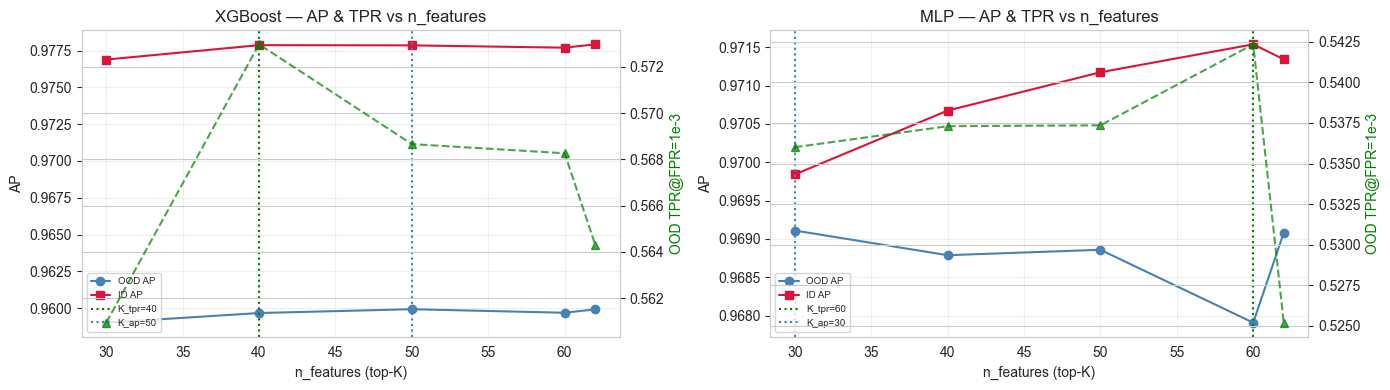

In [34]:
fig, axes = plt.subplots(1, len(selected_models), figsize=(7 * len(selected_models), 4))
if len(selected_models) == 1: axes = [axes]
for ax, name in zip(axes, selected_models):
    sub = ksweep_df.loc[name]
    ax.plot(sub.index, sub["ood_ap"], marker="o", color="steelblue", label="OOD AP")
    ax.plot(sub.index, sub["id_ap"],  marker="s", color="crimson", label="ID AP")
    ax2 = ax.twinx()
    ax2.plot(sub.index, sub["ood_tpr@1e-3"], marker="^", linestyle="--",
             color="green", alpha=0.7, label="OOD TPR@FPR=1e-3")
    ax2.set_ylabel("OOD TPR@FPR=1e-3", color="green")
    ax.axvline(best_k[name]["k_tpr"], color="green", ls=":",
               label=f"K_tpr={best_k[name]['k_tpr']}")
    ax.axvline(best_k[name]["k_ap"],  color="steelblue", ls=":",
               label=f"K_ap={best_k[name]['k_ap']}")
    ax.set_title(f"{name} — AP & TPR vs n_features")
    ax.set_xlabel("n_features (top-K)"); ax.set_ylabel("AP")
    ax.legend(loc="lower left", fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PATHS["plots_dir"] / "ksweep.png", dpi=140)
plt.show()

In [35]:
stage_results["S4_bestk"] = {
    "label": "S4_bestk",
    "n_features": {n: best_k[n]["k_tpr"] for n in selected_models},
    "models": {},
}
for name in selected_models:
    r = ksweep_results[name][best_k[name]["k_tpr"]]
    stage_results["S4_bestk"]["models"][name] = {
        "metrics_id": full_metrics_block(y_test_id, r["probs"]["test_id"], r["threshold"]),
        "metrics_ood": full_metrics_block(y_test_ood, r["probs"]["test_ood"], r["threshold"]),
        "per_family_recall_ood": r["per_family_recall_ood"],
        "threshold": r["threshold"],
        "train_s": r["train_s"],
        "latency": r["latency"],
        "probs": r["probs"],
    }

stage_table = build_stage_table(stage_results)
baseline_ood = {n: baseline_metrics[n]["metrics_ood"]["pr_auc"] for n in MODEL_REGISTRY}
baseline_tpr = {n: baseline_metrics[n]["metrics_ood"]["tpr@fpr=0.001"] for n in MODEL_REGISTRY}
delta_table = stage_table.copy()
delta_table["delta_ood_ap_pp"]  = delta_table.apply(
    lambda r: (r["ood_ap"] - baseline_ood[r["model"]]) * 100, axis=1)
delta_table["delta_ood_tpr_pp"] = delta_table.apply(
    lambda r: (r["ood_tpr@1e-3"] - baseline_tpr[r["model"]]) * 100, axis=1)

print("=== S4_bestk (reused from K-sweep, no retrain) ===")
print(delta_table[delta_table["stage"] == "S4_bestk"][
    ["model", "n_features", "id_ap", "ood_ap", "ood_tpr@1e-3",
     "delta_ood_ap_pp", "delta_ood_tpr_pp", "single_ms", "size_mb"]
].round(4).to_string())

=== S4_bestk (reused from K-sweep, no retrain) ===
      model  n_features   id_ap  ood_ap  ood_tpr@1e-3  delta_ood_ap_pp  delta_ood_tpr_pp  single_ms  size_mb
42  XGBoost          40  0.9779  0.9597        0.5730          -0.0547           -1.4184     1.9710  11.6339
43      MLP          60  0.9715  0.9679        0.5423           0.4856           -3.0432     0.5709   0.1365


In [36]:
pos_map = pd.Series(np.arange(len(cv_idx)), index=cv_idx)

def run_cv(model_name, feature_list, seed=SEED):
    X_cv_raw = full_df.iloc[cv_idx][feature_list].astype("float32")
    y_cv = y_all[cv_idx]
    out = []
    for k in range(N_CV_SPLITS):
        tr_pos = pos_map.loc[cv_folds_npz[f"fold_{k}_train"]].values
        va_pos = pos_map.loc[cv_folds_npz[f"fold_{k}_val"]].values

        X_tr = X_cv_raw.iloc[tr_pos]; X_va = X_cv_raw.iloc[va_pos]
        y_tr = y_cv[tr_pos];          y_va = y_cv[va_pos]

        cfg = MODEL_REGISTRY[model_name]
        if cfg["scale"]:
            sc = StandardScaler().fit(X_tr)
            X_tr = pd.DataFrame(sc.transform(X_tr), columns=feature_list)
            X_va = pd.DataFrame(sc.transform(X_va), columns=feature_list)

        model = fit_model(cfg["builder"](), model_name, X_tr, y_tr, X_va, y_va, seed=seed)
        p = predict_proba_1d(model, X_va)
        out.append({"fold": k,
                    "val_ap": average_precision_score(y_va, p),
                    "val_tpr@1e-3": tpr_at_fpr(y_va, p, TARGET_FPR)})
        print(f"  [{model_name} | {len(feature_list)} feat | fold {k}] "
              f"AP={out[-1]['val_ap']:.4f} | TPR@1e-3={out[-1]['val_tpr@1e-3']:.4f}")
    return pd.DataFrame(out).set_index("fold")


cv_results = {}
for name in selected_models:
    print(f"\n{'=' * 60}\nCV: {name} baseline ({len(PRETRAINED_FEAT)} feat)\n{'=' * 60}")
    cv_results[(name, "baseline")] = run_cv(name, PRETRAINED_FEAT)
    print(f"\n{'=' * 60}\nCV: {name} optimized ({len(optimized_features[name])} feat)\n{'=' * 60}")
    cv_results[(name, "optimized")] = run_cv(name, optimized_features[name])

cv_rows = []
for name in selected_models:
    base = cv_results[(name, "baseline")]; opt = cv_results[(name, "optimized")]
    d_ap_pp  = (opt["val_ap"].values  - base["val_ap"].values).mean() * 100
    d_tpr_pp = (opt["val_tpr@1e-3"].values - base["val_tpr@1e-3"].values).mean() * 100
    try:
        _, p_ap  = wilcoxon(base["val_ap"].values,  opt["val_ap"].values)
        _, p_tpr = wilcoxon(base["val_tpr@1e-3"].values, opt["val_tpr@1e-3"].values)
    except ValueError:
        p_ap = p_tpr = float("nan")
    cv_rows.append({
        "model": name,
        "baseline_n": len(PRETRAINED_FEAT),
        "optimized_n": len(optimized_features[name]),
        "baseline_ap_mean":  base["val_ap"].mean(),
        "baseline_ap_std":   base["val_ap"].std(),
        "optimized_ap_mean": opt["val_ap"].mean(),
        "optimized_ap_std":  opt["val_ap"].std(),
        "delta_ap_pp":  d_ap_pp,
        "p_ap_wilcoxon": p_ap,
        "baseline_tpr_mean":  base["val_tpr@1e-3"].mean(),
        "baseline_tpr_std":   base["val_tpr@1e-3"].std(),
        "optimized_tpr_mean": opt["val_tpr@1e-3"].mean(),
        "optimized_tpr_std":  opt["val_tpr@1e-3"].std(),
        "delta_tpr_pp":  d_tpr_pp,
        "p_tpr_wilcoxon": p_tpr,
    })

cv_summary = pd.DataFrame(cv_rows).set_index("model")
print("\n=== CV summary (5-fold family-aware; same folds e2e_models.ipynb) ===")
print(cv_summary.round(4).to_string())
print("\nWilcoxon n=5 → min achievable p = 0.0625; use |Δ| for gating, report p for transparency.")


CV: XGBoost baseline (130 feat)
  [XGBoost | 130 feat | fold 0] AP=0.8644 | TPR@1e-3=0.3188
  [XGBoost | 130 feat | fold 1] AP=0.9108 | TPR@1e-3=0.3995
  [XGBoost | 130 feat | fold 2] AP=0.9410 | TPR@1e-3=0.5181
  [XGBoost | 130 feat | fold 3] AP=0.8712 | TPR@1e-3=0.3351
  [XGBoost | 130 feat | fold 4] AP=0.9727 | TPR@1e-3=0.6061

CV: XGBoost optimized (40 feat)
  [XGBoost | 40 feat | fold 0] AP=0.8957 | TPR@1e-3=0.4088
  [XGBoost | 40 feat | fold 1] AP=0.9152 | TPR@1e-3=0.3715
  [XGBoost | 40 feat | fold 2] AP=0.9256 | TPR@1e-3=0.2289
  [XGBoost | 40 feat | fold 3] AP=0.8678 | TPR@1e-3=0.3368
  [XGBoost | 40 feat | fold 4] AP=0.9715 | TPR@1e-3=0.4767

CV: MLP baseline (130 feat)
  [MLP | 130 feat | fold 0] AP=0.8194 | TPR@1e-3=0.3468
  [MLP | 130 feat | fold 1] AP=0.9070 | TPR@1e-3=0.4118
  [MLP | 130 feat | fold 2] AP=0.9317 | TPR@1e-3=0.4824
  [MLP | 130 feat | fold 3] AP=0.8616 | TPR@1e-3=0.2572
  [MLP | 130 feat | fold 4] AP=0.9628 | TPR@1e-3=0.6611

CV: MLP optimized (60 feat)
 

Sec 6

In [37]:
final_rows = []
for name in selected_models:
    k_opt = best_k[name]["k_tpr"]
    r = ksweep_results[name][k_opt]
    base = baseline_metrics[name]
    cvr = cv_summary.loc[name]

    delta_tpr_pp = (r["ood_tpr@1e-3"] - base["metrics_ood"]["tpr@fpr=0.001"]) * 100
    delta_ap_pp = (r["ood_ap"] - base["metrics_ood"]["pr_auc"]) * 100
    reduction_pct = (1 - k_opt / len(PRETRAINED_FEAT)) * 100

    gate_tpr = delta_tpr_pp >= -VIABILITY_MAX_DEGRADATION_PP
    gate_reduction = reduction_pct >= VIABILITY_MIN_REDUCTION_PCT
    gate_cv = cvr["delta_ap_pp"] >= -VIABILITY_MAX_DEGRADATION_PP
    viable = gate_tpr and gate_reduction and gate_cv

    m_od = full_metrics_block(y_test_ood, r["probs"]["test_ood"], r["threshold"])
    m_id = full_metrics_block(y_test_id,  r["probs"]["test_id"],  r["threshold"])

    final_rows.append({
        "model": name,
        "n_features_baseline": len(PRETRAINED_FEAT),
        "n_features_optimized": k_opt,
        "reduction_pct": reduction_pct,
        "baseline_id_pr_auc": base["metrics_id"]["pr_auc"],
        "baseline_ood_pr_auc": base["metrics_ood"]["pr_auc"],
        "baseline_ood_tpr@1e-3": base["metrics_ood"]["tpr@fpr=0.001"],
        "baseline_ood_fpr": base["metrics_ood"]["fpr"],
        "baseline_ood_prec@prev=1e-4": base["metrics_ood"]["prec@prev=0.0001"],
        "baseline_ood_brier": base["metrics_ood"]["brier"],
        "baseline_single_ms": base["latency"]["single_ms"],
        "baseline_size_mb": base["latency"]["size_mb"],
        "optimized_id_pr_auc": m_id["pr_auc"],
        "optimized_ood_pr_auc": m_od["pr_auc"],
        "optimized_ood_tpr@1e-3": m_od["tpr@fpr=0.001"],
        "optimized_ood_fpr": m_od["fpr"],
        "optimized_ood_prec@prev=1e-4": m_od["prec@prev=0.0001"],
        "optimized_ood_brier": m_od["brier"],
        "optimized_single_ms": r["latency"]["single_ms"],
        "optimized_size_mb": r["latency"]["size_mb"],
        "delta_ood_tpr_pp": delta_tpr_pp,
        "delta_ood_ap_pp": delta_ap_pp,
        "delta_single_ms_pct": (r["latency"]["single_ms"] / base["latency"]["single_ms"] - 1) * 100,
        "delta_size_mb_pct": (r["latency"]["size_mb"]   / base["latency"]["size_mb"]   - 1) * 100,
        "cv_baseline_ap_mean": cvr["baseline_ap_mean"],
        "cv_baseline_ap_std": cvr["baseline_ap_std"],
        "cv_optimized_ap_mean": cvr["optimized_ap_mean"],
        "cv_optimized_ap_std": cvr["optimized_ap_std"],
        "cv_delta_ap_pp": cvr["delta_ap_pp"],
        "cv_p_wilcoxon": cvr["p_ap_wilcoxon"],
        "gate_tpr_ok": bool(gate_tpr),
        "gate_reduction_ok": bool(gate_reduction),
        "gate_cv_ok": bool(gate_cv),
        "viable": bool(viable),
        "convergence_gap_pp": diag_mlp["gap_pp"] if name == "MLP" else float("nan"),
        "convergence_plateau_epoch": diag_mlp["epochs_run"] if name == "MLP" else float("nan"),
    })

final_df = pd.DataFrame(final_rows).set_index("model")
final_df.to_csv(PATHS["models_dir"] / "optimization_summary.csv")

print("=== Final summary: baseline vs optimized ===")
show_cols = ["n_features_baseline","n_features_optimized","reduction_pct",
             "baseline_ood_pr_auc","optimized_ood_pr_auc","delta_ood_ap_pp",
             "baseline_ood_tpr@1e-3","optimized_ood_tpr@1e-3","delta_ood_tpr_pp",
             "baseline_single_ms","optimized_single_ms","delta_single_ms_pct",
             "baseline_size_mb","optimized_size_mb","delta_size_mb_pct",
             "cv_delta_ap_pp","cv_p_wilcoxon","viable"]
print(final_df[show_cols].round(4).to_string())

viable_models = final_df[final_df["viable"]].index.tolist()
print(f"\nViable: {viable_models}")

if viable_models:
    to_save = {n: optimized_features[n] for n in viable_models}
    with open(PATHS["models_dir"] / "optimized_features.json", "w") as f:
        json.dump(to_save, f, indent=2, ensure_ascii=False)
    print(f"Saved optimized_features.json: { {n: len(v) for n, v in to_save.items()} }")

    for name in viable_models:
        r = ksweep_results[name][best_k[name]["k_tpr"]]
        joblib.dump(r["model"], PATHS["models_dir"] / f"{name}_optimized.pkl")
    print("Saved *_optimized.pkl")

    artifact_v2 = json.loads(json.dumps(artifact))
    artifact_v2["feature_set_version"] = "reduced"
    artifact_v2.setdefault("reduced_models", {})

    artifact_v2["convergence_diagnostic"] = {
        k: v for k, v in diag_mlp.items() if k not in ("aps", "losses")
    }

    for name in viable_models:
        k = best_k[name]["k_tpr"]
        r = ksweep_results[name][k]
        m_od = full_metrics_block(y_test_ood, r["probs"]["test_ood"], r["threshold"])
        m_id = full_metrics_block(y_test_id,  r["probs"]["test_id"],  r["threshold"])
        artifact_v2["reduced_models"][name] = {
            "features": r["features"],
            "n_features": k,
            "threshold": float(r["threshold"]),
            "metrics_id":  {kk: float(vv) for kk, vv in m_id.items()},
            "metrics_ood": {kk: float(vv) for kk, vv in m_od.items()},
            "per_family_recall_ood": {kk: float(vv) for kk, vv in r["per_family_recall_ood"].items()},
            "latency": {kk: float(vv) for kk, vv in r["latency"].items()},
            "cv_summary": {kk: (bool(vv) if isinstance(vv, (bool, np.bool_))
                                else float(vv))
                           for kk, vv in cv_summary.loc[name].items()},
        }

    with open(PATHS["models_dir"] / "model_artifact_v2.json", "w") as f:
        json.dump(artifact_v2, f, indent=2, default=float)
    print("Saved model_artifact_v2.json")

    fam_rows = []
    for name in viable_models:
        base_fam = stage_results["S0_baseline"]["models"][name]["per_family_recall_ood"]
        opt_fam  = ksweep_results[name][best_k[name]["k_tpr"]]["per_family_recall_ood"]
        for fam in sorted(set(base_fam) | set(opt_fam)):
            b = base_fam.get(fam, float("nan")); o = opt_fam.get(fam, float("nan"))
            fam_rows.append({"model": name, "family": fam,
                             "baseline_recall": b, "optimized_recall": o,
                             "delta_pp": (o - b) * 100})
    pd.DataFrame(fam_rows).to_csv(
        PATHS["models_dir"] / "optimization_per_family_recall.csv", index=False)
    print("Saved optimization_per_family_recall.csv")
else:
    print("\nNo model met viability criteria — nothing saved.")

=== Final summary: baseline vs optimized ===
         n_features_baseline  n_features_optimized  reduction_pct  baseline_ood_pr_auc  optimized_ood_pr_auc  delta_ood_ap_pp  baseline_ood_tpr@1e-3  optimized_ood_tpr@1e-3  delta_ood_tpr_pp  baseline_single_ms  optimized_single_ms  delta_single_ms_pct  baseline_size_mb  optimized_size_mb  delta_size_mb_pct  cv_delta_ap_pp  cv_p_wilcoxon  viable
model                                                                                                                                                                                                                                                                                                                                                      
XGBoost                  130                    40        69.2308               0.9602                0.9597          -0.0547                 0.5872                  0.5730           -1.4184              3.9327               1.9710             -49.8826       